In [38]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [7]:
features = pd.read_csv("full_rent_features.csv")
features["log_median_rent_psq"] = np.log(features["median_rent_psq"])

In [14]:
from itertools import combinations

feature_cols = features.drop(
    columns=["lat", "lon", "median_rent", "median_rent_psq", "listing_count", "log_median_rent_psq"]
).columns

formulas = []
log_formulas = []

for i in range(len(feature_cols) + 1):
    for subset in combinations(feature_cols, i):
        if len(subset) == 0:
            formulas.append("median_rent_psq ~ 1")
            log_formulas.append("log_median_rent_psq ~ 1")
        else:
            formulas.append(f"median_rent_psq ~ {' + '.join(subset)}")
            log_formulas.append(f"log_median_rent_psq ~ {' + '.join(subset)}")

In [20]:
models = []
log_models = []

for formula in formulas:
    models.append(smf.ols(formula=formula, data=features).fit().aic)

for formula in log_formulas:
    log_models.append(smf.ols(formula=formula, data=features).fit().aic)

print(f"Best regular model is {formulas[np.argmin(models)]} with AIC: {np.min(models)}")
print(f"Best regular model is {log_formulas[np.argmin(log_models)]} with AIC: {np.min(log_models)}")

Best regular model is median_rent_psq ~ shores_beach_ft + utc_ft + nearest_park_ft with AIC: 159.8809671433784
Best regular model is log_median_rent_psq ~ shores_beach_ft + utc_ft + nearest_park_ft with AIC: -166.64860871896383


In [21]:
models = []
log_models = []

for formula in formulas:
    models.append(smf.ols(formula=formula, data=features).fit().bic)

for formula in log_formulas:
    log_models.append(smf.ols(formula=formula, data=features).fit().bic)

print(f"Best regular model is {formulas[np.argmin(models)]} with BIC: {np.min(models)}")
print(f"Best regular model is {log_formulas[np.argmin(log_models)]} with BIC: {np.min(log_models)}")

Best regular model is median_rent_psq ~ shores_beach_ft + utc_ft with BIC: 169.79724780890163
Best regular model is log_median_rent_psq ~ shores_beach_ft + utc_ft with BIC: -156.27553286921273


In [24]:
model1 = smf.ols(
    formula="log_median_rent_psq ~ shores_beach_ft + utc_ft + nearest_park_ft", data=features
).fit()

model2 = smf.ols(
    formula="log_median_rent_psq ~ shores_beach_ft + utc_ft", data=features
).fit()

print(model1.summary())
print(model2.summary())

                             OLS Regression Results                            
Dep. Variable:     log_median_rent_psq   R-squared:                       0.281
Model:                             OLS   Adj. R-squared:                  0.264
Method:                  Least Squares   F-statistic:                     16.82
Date:                 Fri, 05 Jun 2026   Prob (F-statistic):           2.77e-09
Time:                         10:04:25   Log-Likelihood:                 87.324
No. Observations:                  133   AIC:                            -166.6
Df Residuals:                      129   BIC:                            -155.1
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           1.5498      

In [29]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_calculator(model):
    X = model.model.exog
    names = model.model.exog_names

    vif = pd.DataFrame({
        "Variable": names,
        "VIF": [variance_inflation_factor(X, i)
                for i in range(X.shape[1])]
    })

    return vif

print(vif_calculator(model1))
print("\n")
print(vif_calculator(model2))

          Variable        VIF
0        Intercept  22.360190
1  shores_beach_ft   1.281905
2           utc_ft   1.290400
3  nearest_park_ft   1.023586


          Variable        VIF
0        Intercept  20.603780
1  shores_beach_ft   1.264772
2           utc_ft   1.264772


Text(0, 0.5, 'Residuals')

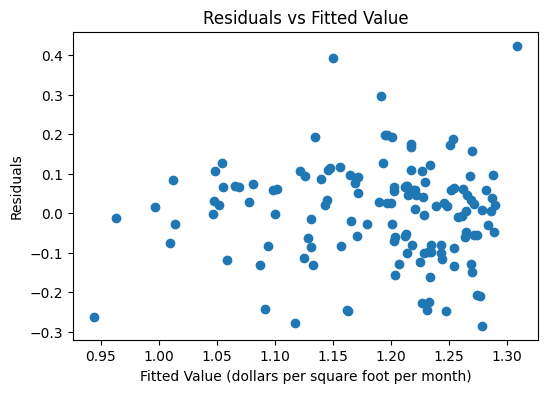

In [35]:
import matplotlib.pyplot as plt

fitted = model1.fittedvalues
residuals = model1.resid

plt.figure(figsize=(6, 4))
plt.scatter(fitted, residuals)
plt.title("Residuals vs Fitted Value")
plt.xlabel("Fitted Value (dollars per square foot per month)")
plt.ylabel("Residuals")

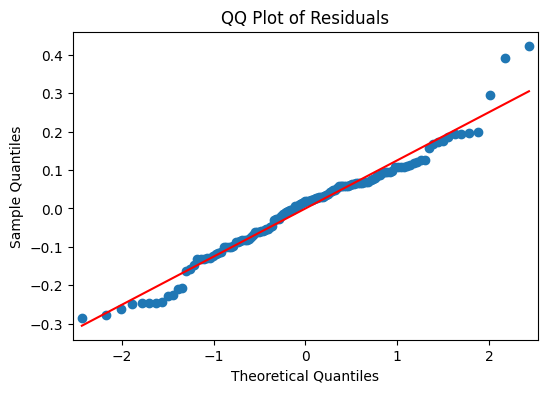

In [47]:
fig, ax = plt.subplots(figsize=(6, 4))
sm.qqplot(model1.resid, line="s", ax=ax)
plt.title("QQ Plot of Residuals");

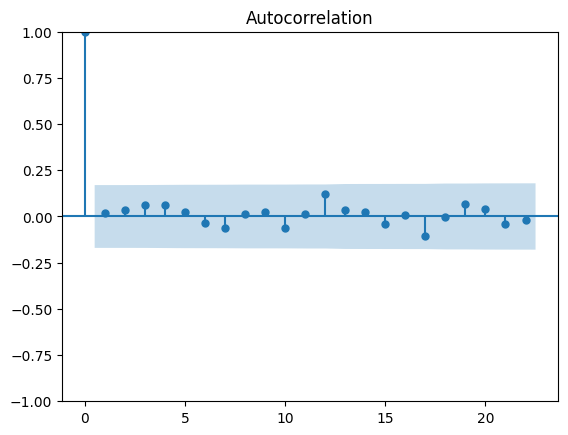

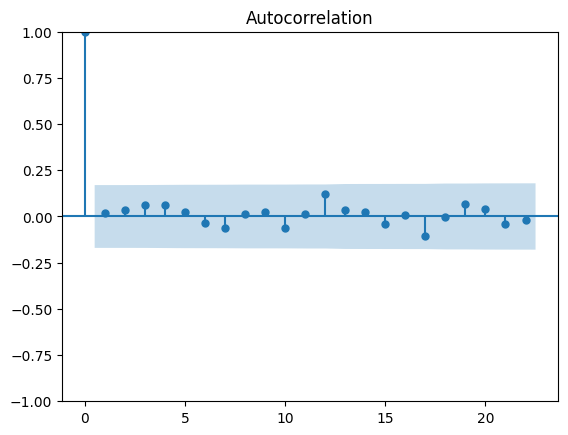

In [36]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(features["log_median_rent_psq"])

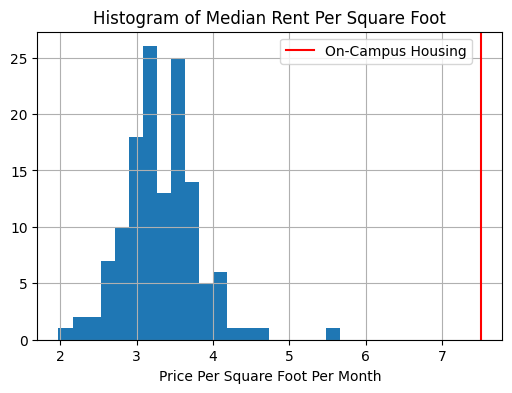

In [59]:
fig, ax = plt.subplots(figsize=(6,4))
features["median_rent_psq"].hist(ax=ax, bins=20)
plt.axvline(x=7.51, color="red", label="On-Campus Housing")
plt.title("Histogram of Median Rent Per Square Foot")
plt.xlabel("Price Per Square Foot Per Month")
plt.legend(loc="upper right", bbox_to_anchor=(0.95, 1));

In [55]:
pred_df = pd.DataFrame({
    "shores_beach_ft": [12038],
    "utc_ft": [10616],
    "nearest_park_ft": [436] 
})

pred = model1.get_prediction(pred_df)
summary = pred.summary_frame(alpha=0.01)
print(summary)

       mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0  1.126478  0.025849       1.058897       1.194059      0.786548   

   obs_ci_upper  
0      1.466408  
